# The titration curve → `titration.pdf`

The fit: exponential-tilt sampling on the within-animal **rank** of ρ, K = 186 / 62 distinct
units per sweep point, **100 training repeats** per sweep point.

## The sweep

Sweep point *x* is the target **weighted mean rank**: λ(x) inverts
`m(λ) = 1/(1 − e^−λ) − 1/λ`, the mean of a density ∝ e^{λr} on the unit interval. Ranks are
uniform on [0, 1] by construction, so that inverse uses **no data** — one λ grid serves both
animals, and **λ(0.5) = 0 exactly**. x = 0.5 is therefore the unbiased population, and the
question "is the recorded composition optimal?" becomes "**can any other composition decode
better?**" — asked against a landmark fixed by construction rather than estimated from the
neurons.

## Re-running this notebook

The fit lives in `cache/figures/figure_3/efficient_coding/dataframes/` and is never recomputed
here (`regenerate.py` writes it). The notebook's own expensive step — loading the neuron pool —
is cached separately in `derived/` beside it, so **changing `INSET_SEED` redraws the example
draws and touches nothing else**. `tl.clear_cache()` drops the derived files and leaves the fit
alone.

The figure is written to `titration.pdf` next to this notebook, overwriting the previous
version.


In [1]:
import sys
from pathlib import Path

import pandas as pd
from matplotlib import pyplot as plt

# The repository root (where paths.py lives), found from this notebook's folder.
_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'paths.py').exists())
sys.path.insert(0, str(_root))
import paths
sys.path.insert(0, str(paths.FIGURES / 'figure_3/efficient_coding'))
sys.path.insert(0, str(paths.FIGURES / 'figure_3'))
sys.path.insert(0, str(paths.FIGURES / 'figure_3/model_comparison'))
import common
import titration_lib as tl

common.set_style()
pd.set_option('display.width', 240)

# ── CONFIG ───────────────────────────────────────────────────────────────────
INSET_SEED = 10              # change this to redraw the example insets; nothing else moves
INSET_XS = (0.1, 0.5, 0.9)  # which sweep points get an inset below the curve
INSET_SUBJECT = 'Perle'     # whose pool the insets draw from; the scheme is identical in both
FIGSIZE = (3.0, 2.7)        # the curve panel; the inset row is added below this height
XLABEL = 'Subsampling ratio'
YLABEL = 'Stimulus decoder error (°)'
XTICKS = (0.2, 0.5, 0.8)
# How dark the insets' tilt shading gets: it truncates the grey ramp, so 1.0 takes the densest
# wedge to black and lower values lift the whole scale toward white. Relative shades are
# unchanged either way — this is luminance only, not the mapping from density to grey.
INSET_SHADE_MAX = 0.6
INSET_ROW_HEIGHT = 0.45     # the inset row's height, relative to the curve's
INSET_GAP = 0.07            # space between the x label and the insets (layout hspace)
# Where the middle grey rule starts, in POINTS BELOW THE BOTTOM OF THE X LABEL: 0 starts it right at
# the label, larger values start it lower, negative values start it higher (into the label).
MIDDLE_LINE_START_PT = 6.0
LINE_GREY = 0.5             # grey level of the rules to the insets: 0 is black, 1 is white
# The black double arrow over the curve and its two labels, in the curve's AXES FRACTIONS:
# x = 0 is its left edge and 1 its right, y = 1 its top, so larger y sits higher above the plot.
ARROW_X = (0.02, 0.98)       # the labels: left edge of "Retinotopic", right edge of "Relational"
ARROW_LENGTH = 0.8           # the arrow's length, centred between the ARROW_X ends
ARROW_HEAD_SIZE = 14         # arrowhead size (matplotlib mutation_scale)
ARROW_Y = 1.02
ARROW_LABEL_Y = 1.05
ARROW_LABEL_FONTSIZE = 12
ARROW_LABEL_WEIGHT = 1.0   # 'normal' or 'bold'
# Extra thickness on top of ARROW_LABEL_WEIGHT, in points of outline: 0 adds none, ~0.3-1 is a
# gentle-to-heavy boost. Arial has only regular and bold, so this is the continuous knob.
ARROW_LABEL_STROKE = 0.3
OUTPUT = 'titration.pdf'    # written next to this notebook, overwriting any previous version

units = tl.cached_units()
pop = tl.cached_population(units)
d = tl.load()
r0 = d.iloc[0]
print(f'{len(d)} rows | K={r0.param_n_units_matched} repeats={r0.param_repeats} '
      f'tilt_on={r0.param_tilt_on} hidden={r0.param_hidden} '
      f'n_samples={r0.param_n_samples} rotations={r0.param_rotation_bins}')
display(pop.round(4))
display(tl.lam_grid().round(4))

1800 rows | K=62 repeats=100 tilt_on=rank hidden=64,64 n_samples=500 rotations=36


,subject,n,mean_rho,lo,hi
0,Monkey P,928,0.5732,0.5591,0.5868
1,Monkey E,311,0.5453,0.5221,0.5678


,x,lam
0,0.1,-9.9954
1,0.2,-4.8010
2,0.3,-2.6721
3,0.4,-1.2299
4,0.5,0.0000
5,0.6,1.2299
6,0.7,2.6721
7,0.8,4.8010
8,0.9,9.9954


## The figure

The titration curve above, one **example draw** per inset sweep point below it. The insets are
single draws from `INSET_SUBJECT`'s pool — what one training run actually receives — so they move
with `INSET_SEED`; the grey rule above each one ties it to its point on the curve. One animal's
pool is shown because the sampling scheme is identical in both.

The x axis is the **realized mean rank of the draw**, not the target. The two differ at the ends
because drawing K distinct units without replacement caps the realized mean rank at
`[K/2n, 1 − K/2n]`; plotting the target would overstate the range by hiding that.

Both animals share one axis and are told apart by marker shape and line style; the band is
±1 s.e.m. of the mean over the 100 training repeats. The unbiased population is at rank 0.5,
exact by construction (λ(0.5) = 0) — whether any composition decodes *better* than it is the
cell below, not something to read off the figure.

In each inset the **grey shading is the tilt density**, and depends on the polar angle alone: a
point at angle θ has ρ = (2/π)·θ, that ρ has a rank in this animal's pool, and the tilt weights it
by `exp(λ·rank)`. It is normalised as a density on rank, so **1 = "as likely as under no tilt"**
and the middle panel is *exactly* uniform. The log scale is shared across the three panels
(1/10 to 10), so they compare directly: white is a region the tilt has emptied, dark is one it
has concentrated into. The red dots are one draw from that weight field.


saved titration.pdf


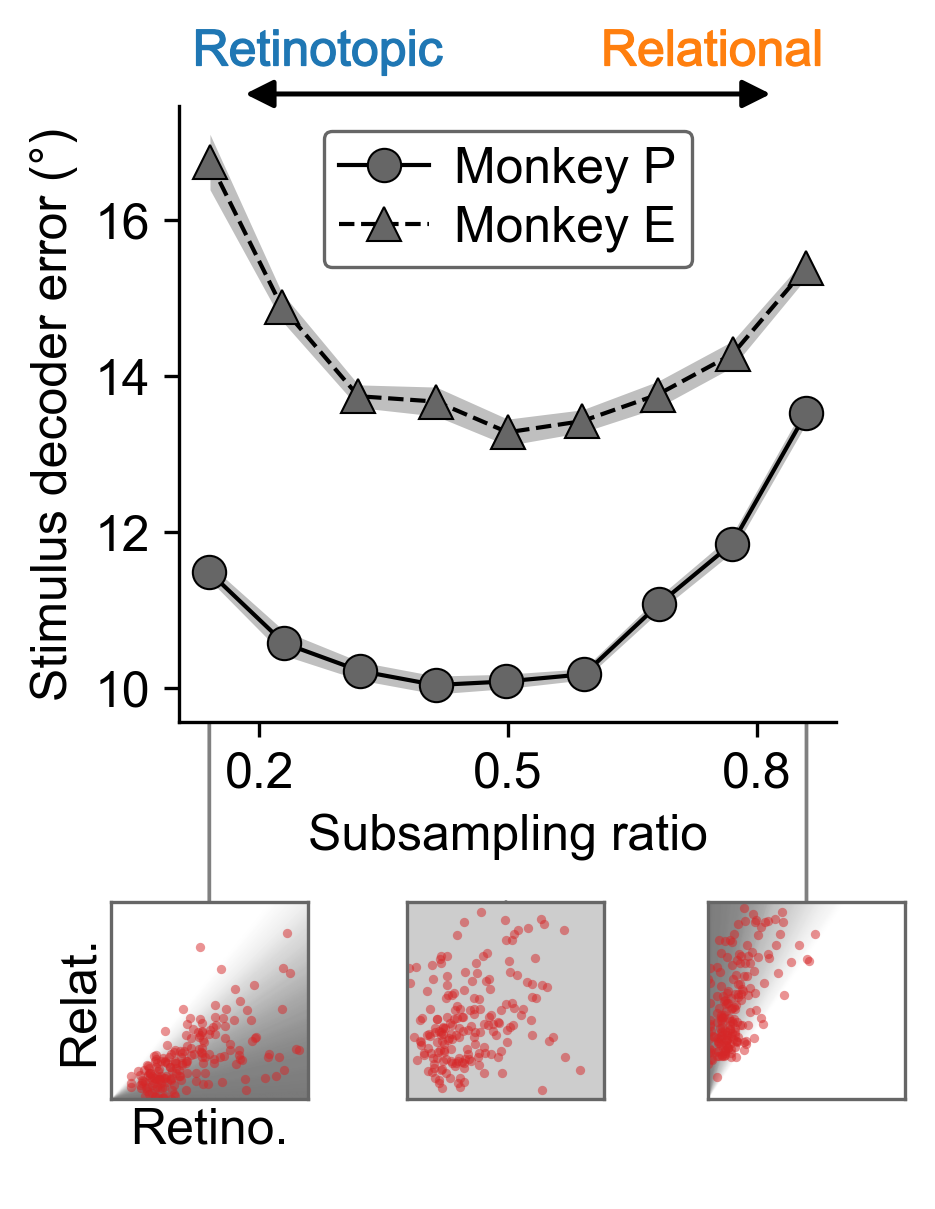

In [2]:
fig = tl.plot_figure(units, inset_xs=INSET_XS, seed=INSET_SEED,
                     inset_subject=INSET_SUBJECT, figsize=FIGSIZE,
                     xlabel=XLABEL, ylabel=YLABEL, xticks=XTICKS,
                     inset_shade_max=INSET_SHADE_MAX, inset_row_height=INSET_ROW_HEIGHT,
                     row_gap=INSET_GAP, arrow_x=ARROW_X, arrow_y=ARROW_Y,
                     arrow_label_y=ARROW_LABEL_Y, arrow_label_fontsize=ARROW_LABEL_FONTSIZE,
                     arrow_label_weight=ARROW_LABEL_WEIGHT, arrow_label_stroke=ARROW_LABEL_STROKE,
                     arrow_length=ARROW_LENGTH, arrow_head_size=ARROW_HEAD_SIZE,
                     connector_label_pad=MIDDLE_LINE_START_PT, connector_color=str(LINE_GREY))
common.save(fig, OUTPUT)
plt.show()

## Is any composition better than the unbiased one?

The direct question: *could the animal decode better by shifting its mix?*

Each sweep point is tested against x = 0.5 with Welch's t over the 100 training repeats,
**Holm-corrected** within animal. Unpaired, because repeat *r* at two different sweep points
shares no seed — each point draws its own neurons and trains its own network — so the
across-repeat spread includes the "which K neurons were drawn" variance, which is exactly what
belongs in the denominator: the claim is about a *population of that composition*, averaged over
which neurons realize it.

Holm rather than Benjamini–Hochberg because the headline is a family-wise claim ("is **any**
point better?"), and Holm is the more conservative side to err on for a negative result.


In [3]:
verdict = tl.unbiased_verdict(d)
display(verdict.round(4))
for _, r in verdict.iterrows():
    print(f'{r.subject}: {int(r.n_worse)} of 8 points significantly WORSE than unbiased, '
          f'{int(r.n_better)} significantly BETTER, {int(r.n_ns)} indistinguishable.')
    verb = 'beats' if r.best_challenger_delta < 0 else 'trails'
    print(f'    the best challenger is x = {r.best_challenger_x:.1f}, which {verb} the unbiased '
          f'point by {abs(r.best_challenger_delta):.3f}° '
          f'({100 * abs(r.best_challenger_delta) / r.ref_mean:.2f}% of its error) — '
          f'Holm p = {r.best_challenger_p_holm:.3f}\n')
n_better_total = int(verdict.n_better.sum())
print('=' * 72)
print(f'No sweep point is significantly better than the unbiased population in either animal.'
      if n_better_total == 0 else
      f'{n_better_total} point(s) significantly better than unbiased — see the table above.')
print('=' * 72)


,subject,n_worse,n_better,n_ns,best_challenger_x,best_challenger_delta,best_challenger_p_holm,ref_mean
0,Monkey P,5,0,3,0.4,-0.0460,1.0000,10.0866
1,Monkey E,4,0,4,0.6,0.1436,0.5195,13.2795


Monkey P: 5 of 8 points significantly WORSE than unbiased, 0 significantly BETTER, 3 indistinguishable.
    the best challenger is x = 0.4, which beats the unbiased point by 0.046° (0.46% of its error) — Holm p = 1.000

Monkey E: 4 of 8 points significantly WORSE than unbiased, 0 significantly BETTER, 4 indistinguishable.
    the best challenger is x = 0.6, which trails the unbiased point by 0.144° (1.08% of its error) — Holm p = 0.519

No sweep point is significantly better than the unbiased population in either animal.


### What this notebook does not establish

* the `cv_r2` gradient along ρ is untouched by any of this;
* independent Poisson noise, and the task's own stimulus distribution;
* capacity is probed only downward — the decoder sits ~3× above the Cramér–Rao bound, so part of
  a difference between compositions could be learnability rather than information;
* the ρ coordinate was chosen among several candidate coordinates (a forking path);
* the tilt still confounds mean composition with ρ-*spread*, though more weakly than a hard rank
  wedge would; only a two-parameter tilt would remove it.
